In [ ]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: scikit-image in c:\users\lenovo\appdata\local\programs\python\python310\lib\site-packages (0.25.2)



You should consider upgrading via the 'c:\Users\Lenovo\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


# Kode 2.1 Pemisahan kanal dan Kontras Bercak 

In [2]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src" / "utils_cv.py").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))
print(Path.cwd())

c:\Users\Lenovo\Documents\GitHub\SIMUTEH-2330511060\notebook


KB kanal B   : 2.91
KB kanal G   : 1.18
KB kanal R   : 9.34
KB kanal Gray: 4.69
KB kanal H   : 6.97
KB kanal S   : 1.44
KB kanal V   : 2.92


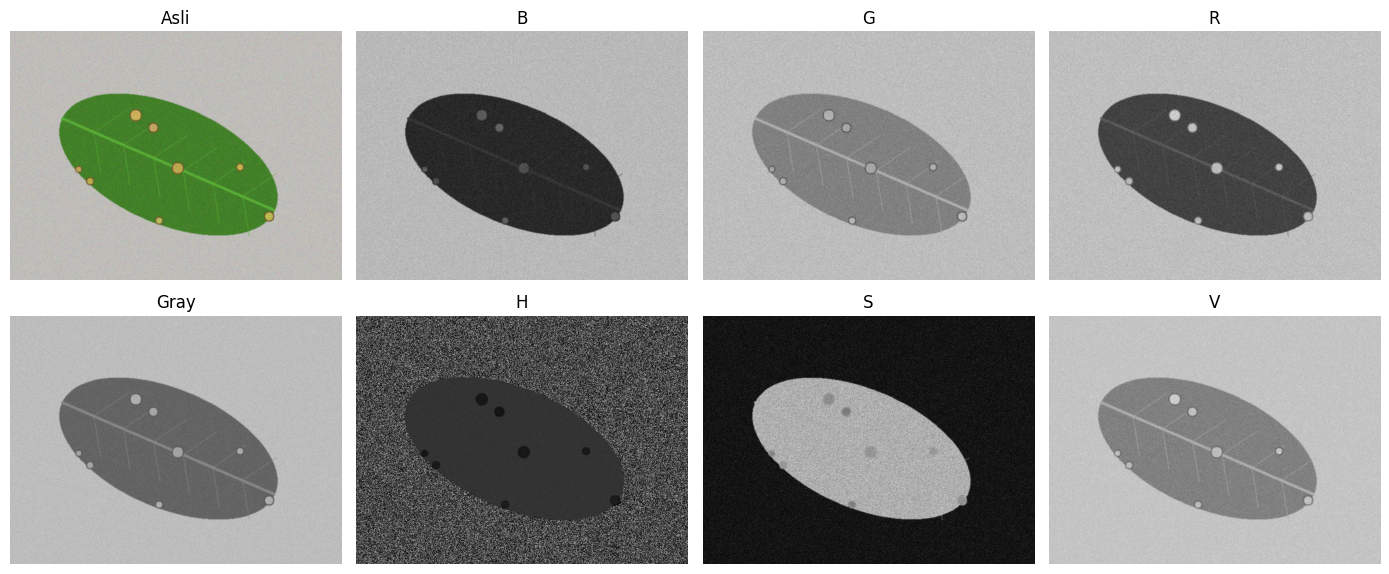

In [3]:
import cv2
from utils_cv import baca, tampil, kontras_bercak
  
nama = "teh_041.png"                 # kelas berat, kondisi normal 
img = baca(f"../data/sintetis/citra/{nama}") 
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0) 
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0) 
  
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) 
b, g, r = cv2.split(img) 
h, s, v = cv2.split(hsv) 
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v} 
  
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), 
       baris=2, ukuran=(14, 6)) 
for nm, c in kanal.items(): 
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}") 

# Kode 2.2 Sampling dan kuantisasi

In [13]:
import numpy as np
# sampling: perkecil lalu perbesar kembali ke ukuran semula 
for fx in [0.5, 0.2, 0.1, 0.05]: 
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA) 
    besar = cv2.resize(kecil, gray.shape[::-1], 
                       interpolation=cv2.INTER_NEAREST) 
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}") 
  
  
# kuantisasi: sisakan k bit 
for k in [1, 2, 3, 4, 8]: 
    langkah = 256 // (2 ** k) 
    kuant = (gray // langkah) * langkah 
    print(f"k={k}: {len(np.unique(kuant))} level, " 
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.52
fx=0.2: ukuran (96, 128), KB=4.84
fx=0.1: ukuran (48, 64), KB=3.19
fx=0.05: ukuran (24, 32), KB=1.40
k=1: 2 level, KB=4.13
k=2: 3 level, KB=4.13
k=3: 5 level, KB=2.53
k=4: 10 level, KB=4.14
k=8: 142 level, KB=4.69


# Kode 2.3 Rerata KB per kanal dan per kondisi

In [14]:
import pandas as pd 
  
def semua_kanal(img): 
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) 
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv) 
    return {"B": b, "G": g, "R": r, 
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 
            "H": h, "S": s, "V": v} 
  
label = pd.read_csv("../data/sintetis/label.csv") 
baris = [] 
for _, d in label[label.kelas == "berat"].iterrows(): 
    im = baca(f"../data/sintetis/citra/{d.nama_file}") 
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0) 
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()} 
kb["kondisi"] = d.kondisi_cahaya 
baris.append(kb) 
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2) 
print(tabel_kb) 
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv") 

             B     G     R  Gray     H     S     V
kondisi                                           
bayangan  1.47  0.03  4.01   1.2  3.71  1.07  0.65
